# NSF intrinsic NII6583 dispersion by global stellar mass - 2026-10-26

Retain the source analysis through **cell 8 (one-based)** of
`20261022_check_post_peak_intrinsic_NII6583_dispersion.ipynb`, including the
two original all-mass stage-profile figures. Then repeat those figures within
three **global galaxy stellar-mass** bins, using `logMstar` from
`mauve_master_wiki_newclass.fits` (log10 total stellar mass in solar masses):
**<9.5**, **9.5 <= logMstar <= 10.5**, and **>10.5**. Both boundary values
belong to the middle bin. These are galaxy selections; the horizontal axes
remain local stellar surface density and deprojected R/Re.

Motivation: [linked discussion](https://chatgpt.com/c/6adeb39a-8288-83ec-8f3b-d3a96436b939)
asks whether stage trends, especially radial trends, persist at comparable
global stellar mass. This is a coarse mass stratification, not exact matching
of the mass distributions within each bin.

Preserve inclination <80 degrees, finite SNR_POSTFIT >25, finite local stellar
density and gas BIN_ID, and MASK==0. SF requires finite HII SFR, EW(Halpha)>6
Angstrom and intrinsic Halpha sigma<45 km/s; ND fails either Balmer detection
threshold; NSF is the remaining usable population. Dispersion uses finite positive
sqrt(NII6583_SIGMA**2 - NII6583_SIGMA_CORR**2) on NSF spaxels.
No additional dispersion ceiling or NII flux-S/N selection is applied.

Profiles retain shared 0.25-wide bins across the complete finite local-density
and radius ranges. Axis display limits remain 6-11 and 0-2 respectively.
Per-galaxy/bin support requires >=50 usable spaxels and >=20 finite NSF
dispersion spaxels. Equal-galaxy profiles average supported galaxy means;
pooled-spaxel profiles use the corresponding spaxel counts. Bands are the
16th-84th percentiles of 10,000 whole-product bootstrap draws, resampling
only products in the given stage and global-mass bin. There is no additional
minimum number of galaxies. Unsupported bins remain blank. A single contributing
product cannot provide a between-galaxy uncertainty estimate, even when the
bootstrap band collapses to zero width; support tables report these cases.

**NGC4567_8:** as explicitly requested, assign the combined product to the
middle bin because both component catalogue masses lie there. Do not sum their
masses for bin assignment. Retain the source minimum component R/Re geometry,
and treat this combined product as one bootstrap unit. The membership table
lists both component masses so this exception is auditable.

Only stage profiles through source cell 8 and their global-mass repeats are
plotted. Later source maps, distributions, dispersion ceilings and flux-S/N
variants are omitted. FITS inputs and the source notebook are read only.
Figures are embedded; optional PNG/PDF export is disabled by default.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / '20261026_NII6583_dispersion_by_global_mass_assets'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
INTENSITY_EDGES = np.arange(7.0,9.5+0.125,0.25)
INTENSITY_MIN_USABLE = 50
INTENSITY_MIN_SF_SUPPORT = 20  # reported support; not an extra stage/bin plotting gate
INTENSITY_N_BOOTSTRAP = 10_000  # whole-galaxy bands for the new reference-panel estimator
PROFILE_X_LIMITS = {'log_sigma_star': (6.0, 11.0), 'radius_re': (0.0, 2.0)}
PROFILE_BIN_WIDTH = 0.25
FRACTION_EDGES = {}  # populated from the complete finite data ranges in cell 5
FRACTION_MIN_USABLE = 50
FRACTION_N_BOOTSTRAP = 10_000
CATEGORY_COLORS = {'SF':'#2166ac','ND':'#e69f00','NSF':'#b2182b'}
NSF_RAW_LINES = ('HA6562','HB4861','OIII5006','NII6583','SII6716','SII6730')
NSF_LINE_ORDER = ('HA6562','HB4861','OIII5006','NII6583','SII_SUM')
NSF_LINE_LABELS = {'HA6562':r'H$\alpha$','HB4861':r'H$\beta$','OIII5006':r'[O III]$\lambda5007$',
    'NII6583':r'[N II]$\lambda6583$','SII_SUM':r'[S II]$\lambda\lambda6716,6731$'}
NSF_MIN_COMMON = 20
NSF_N_BOOTSTRAP = 10_000
NSF_EXTRA_DIAGNOSTICS = ('EW_Ha','sigma_NII6583_intrinsic','SII_doublet')
NSF_EXTRA_MIN_PIXELS = 20
NSF_EXTRA_N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}
EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma for SF classification only
BIN_WIDTH = 0.15
MIN_SF_PER_BIN = 10
TREND_X_RANGE = (5.0, 11.0)  # no percentile truncation
PESSA_SLOPE, PESSA_INTERCEPT = 1.05, -10.63
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})


# Bounded follow-up regions; retain the original <8 and >1 endpoint conventions.
LOW_MASS_MIN = 7.5
LOW_MASS_LIMIT = 8.0
OUTER_RADIUS_LIMIT = 1.0
OUTER_RADIUS_MAX = 1.5
HIGH_SIGMA_LIMIT = 100.0
SAVE_FIGURES = False
NSF_EXTRA_DIAGNOSTICS = ('sigma_NII6583_intrinsic',)
from matplotlib.colors import PowerNorm

def save_figure(fig, stem):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=200, bbox_inches='tight')

def dispersion_region_masks(mass, radius, base):
    """Separate bounded NSF regions; their footprints may overlap."""
    return {
        'logSigmaStar_7p5_to_8': base & (mass >= LOW_MASS_MIN) & (mass < LOW_MASS_LIMIT),
        'R_over_Re_1_to_1p5': base & (radius > OUTER_RADIUS_LIMIT) & (radius <= OUTER_RADIUS_MAX),
    }


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))

## Load the source selection and retain spatial coordinates
The loader and geometry helpers are copied from source cells 2-3; unrelated line diagnostics and rSFMS calculations are omitted.

In [3]:
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
post_peak_maps = {}
fraction_galaxy_rows = []
nsf_line_galaxy_rows = []
nsf_line_provenance_rows = []
nsf_extra_galaxy_rows = []

sf_x_parts, sf_y_parts, nd_x_parts, nd_y_parts = [], [], [], []
sf_group_parts, nd_group_parts = [], []
nsf_x_parts, nsf_y_parts, nsf_group_parts = [], [], []
inventory_rows, count_rows = [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))

inventory = pd.DataFrame(inventory_rows)
# Shared bins span every finite mass/radius value in included product maps.
# No mass or radius selection is applied to the dispersion profiles.
profile_bounds = {key: [np.inf, -np.inf] for key in ('log_sigma_star', 'radius_re')}
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    mass_for_edges, header_for_edges = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    radius_for_edges = calculate_deprojected_radius(
        mass_for_edges.shape, header_for_edges,
        geometry.loc[geometry.notebook_product_id.eq(record.galaxy)])
    for variable, values in (('log_sigma_star', mass_for_edges), ('radius_re', radius_for_edges)):
        finite = values[np.isfinite(values)]
        if finite.size:
            profile_bounds[variable][0] = min(profile_bounds[variable][0], float(finite.min()))
            profile_bounds[variable][1] = max(profile_bounds[variable][1], float(finite.max()))
for variable, (lower, upper) in profile_bounds.items():
    if not np.isfinite([lower, upper]).all():
        raise ValueError(f'{variable}: no finite profile coordinates')
    first_bin = int(np.floor(lower / PROFILE_BIN_WIDTH))
    # Final edge is strictly above the maximum, including exact edge values.
    last_bin = int(np.floor(upper / PROFILE_BIN_WIDTH)) + 1
    FRACTION_EDGES[variable] = np.arange(first_bin, last_bin + 1) * PROFILE_BIN_WIDTH
del mass_for_edges, radius_for_edges
print('Full-range profile bin edges:', {key: (edges[0], edges[-1]) for key, edges in FRACTION_EDGES.items()})

for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    meta = product_meta[gal]
    paths = {key: Path(getattr(record, key)) for key in ('mass', 'gas', 'ew', 'sfh', 'mask')}
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'NII6583_SIGMA', 'NII6583_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    radius_re = calculate_deprojected_radius(mass.shape,mass_hdr,geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    # Preserve the source Halpha-based SF/ND/NSF classification.
    ha_sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    ha_sigma = np.sqrt(np.where(np.isfinite(ha_sigma2) & (ha_sigma2 > 0), ha_sigma2, np.nan))
    sigma2 = arrays['NII6583_SIGMA']**2 - arrays['NII6583_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(ha_sigma) & (ha_sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))

    sigma_valid = nsf & np.isfinite(sigma)
    assert (sigma[sigma_valid] > 0).all()
    for variable, values in [('log_sigma_star', mass), ('radius_re', radius_re)]:
        edges = FRACTION_EDGES[variable]
        n_valid, _ = np.histogram(values[valid & np.isfinite(values)], bins=edges)
        selected = sigma_valid & np.isfinite(values)
        n_diag, _ = np.histogram(values[selected], bins=edges)
        total, _ = np.histogram(values[selected], bins=edges, weights=sigma[selected])
        assert n_diag.sum() == selected.sum() and np.all(n_diag <= n_valid)
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            nsf_extra_galaxy_rows.append(dict(galaxy=gal, stage=meta['stage'], variable=variable,
                diagnostic='sigma_NII6583_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(n_valid[j]), N_diag=int(n_diag[j]), sum_primary=float(total[j]),
                mean_primary=float(total[j]/n_diag[j]) if n_diag[j] else np.nan,
                supported=bool(n_valid[j] >= FRACTION_MIN_USABLE and n_diag[j] >= NSF_EXTRA_MIN_PIXELS)))
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
        usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()), NSF=int(nsf.sum()),
        N_sigma=int(sigma_valid.sum())))
    if meta['stage'] == 3:
        post_peak_maps[gal] = dict(mass=mass.copy(), radius=radius_re.copy(), sigma=sigma.copy(),
            selected=sigma_valid.copy(), header=mass_hdr.copy(),
            low_snr=np.isfinite(snr_postfit) & (snr_postfit < SNR_POSTFIT_MIN))

inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
nsf_extra_by_galaxy = pd.DataFrame(nsf_extra_galaxy_rows)
assert len(counts) and len(post_peak_maps), 'No complete included products or post-peak maps'
assert (counts.usable == counts.SF + counts.ND + counts.NSF).all()
assert counts.inclination.lt(80).all()
assert set(post_peak_maps) == set(counts.loc[counts.stage.eq(3), 'galaxy'])
display(inventory[['galaxy', 'stage', 'inclination', 'status']])
display(counts)
print('Included products:', len(counts), '; post-peak:', len(post_peak_maps))

Full-range profile bin edges: {'log_sigma_star': (np.float64(5.75), np.float64(11.25)), 'radius_re': (np.float64(0.0), np.float64(12.25))}
Included products: 26 ; post-peak: 13


,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,usable,SF,ND,NSF,N_sigma
0,IC3392,3,68.0,57030,13888,34019,9123,9123
1,NGC4064,3,70.0,128406,3273,91212,33921,33921
2,NGC4189,1,42.0,120917,80671,6234,34012,34012
3,NGC4254,1,39.0,637876,466023,8495,163358,163358
4,NGC4293,3,67.0,253797,471,189926,63400,63400
5,NGC4294,1,74.0,123446,67512,4508,51426,51426
6,NGC4298,2,52.0,232720,138402,51214,43104,43104
7,NGC4321,1,32.0,789734,375302,84777,329655,329655
8,NGC4351,1,48.0,78282,29731,31869,16682,16682
9,NGC4380,3,61.0,233695,56075,126430,51190,51190


## Adapt the cell 23 dispersion profiles to [N II] lambda6583
Source cell 22 aggregation is retained, restricted to intrinsic NII6583 dispersion.

In [4]:
assert (nsf_extra_by_galaxy.N_diag<=nsf_extra_by_galaxy.N_valid).all()
assert np.array_equal(nsf_extra_by_galaxy.supported,
    (nsf_extra_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(nsf_extra_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
extra_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.stage.eq(stage)&
                        nsf_extra_by_galaxy.variable.eq(variable)&nsf_extra_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(nsf_extra_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    extra_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
nsf_extra_profiles=pd.DataFrame(extra_profile_rows)
assert len(nsf_extra_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=nsf_extra_profiles.N_gal_support.gt(0)
assert np.isfinite(nsf_extra_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (nsf_extra_profiles.loc[supported,'lo']<=nsf_extra_profiles.loc[supported,'hi']).all()
assert nsf_extra_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&nsf_extra_profiles.diagnostic.isin(['sigma_NII6583_intrinsic','SII_doublet'])
assert (nsf_extra_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(nsf_extra_profiles)
print('NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed')

NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed


,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.25,6.50,6.375,1,443,6585,39.690235,39.690235,39.690235
3,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.50,6.75,6.625,1,1007,6585,36.738324,36.738324,36.738324
4,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.75,7.00,6.875,2,10281,9011,37.910661,36.055778,39.765544
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


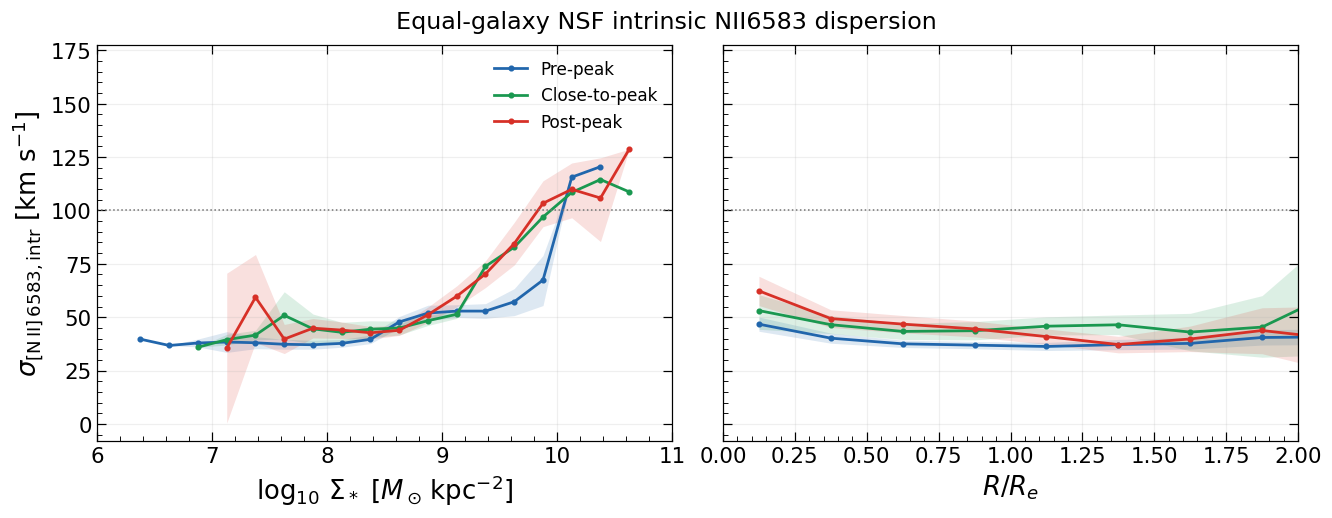

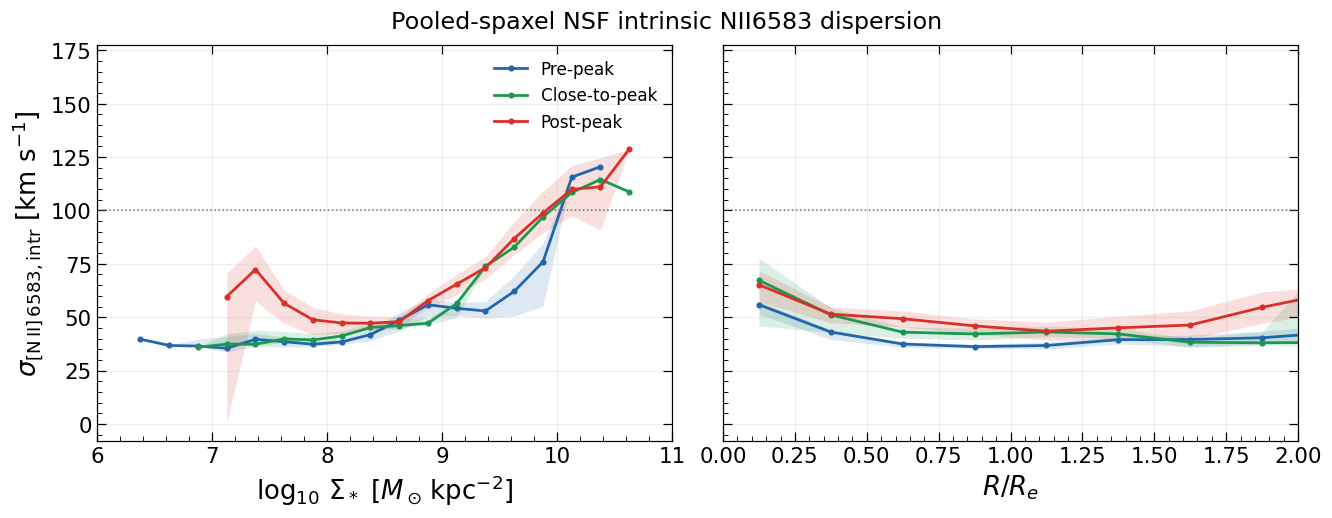

In [5]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = nsf_extra_profiles.loc[nsf_extra_profiles.branch.eq(branch) &
                nsf_extra_profiles.stage.eq(stage) & nsf_extra_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{[N\,II]}\,6583,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + ' NSF intrinsic NII6583 dispersion')
    save_figure(fig, 'NSF_intrinsic_NII6583_dispersion_' + branch)
    plt.show(); plt.close(fig)

## Global stellar-mass membership and stage counts

Join the catalogue by physical galaxy name, then join membership to the included
products already loaded in cell 5. Keep original all-mass tables intact.
The middle bin includes both endpoints; missing or ambiguous mass membership
raises an error rather than silently dropping a product.


In [6]:
GLOBAL_MASS_ORDER = ('low', 'middle', 'high')
GLOBAL_MASS_LABELS = {
    'low': r'$\log_{10}(M_*/M_\odot)<9.5$',
    'middle': r'$9.5\leq\log_{10}(M_*/M_\odot)\leq10.5$',
    'high': r'$\log_{10}(M_*/M_\odot)>10.5$',
}

def global_mass_bin(log_mass):
    if not np.isfinite(log_mass):
        raise ValueError('Global stellar mass must be finite')
    if log_mass < 9.5:
        return 'low'
    return 'middle' if log_mass <= 10.5 else 'high'

assert [global_mass_bin(x) for x in (9.49, 9.5, 10.5, 10.51)] == [
    'low', 'middle', 'middle', 'high']
with fits.open(CATALOG_PATH) as h:
    names = [str(row['Galaxy']).strip() for row in h[1].data]
    assert len(names) == len(set(names)), 'Duplicate catalogue names'
    catalog_logmstar = {str(row['Galaxy']).strip(): float(row['logMstar'])
                        for row in h[1].data}

membership_rows = []
for gal in counts.galaxy.sort_values():
    components = geometry.loc[geometry.notebook_product_id.eq(gal), 'galaxy'].tolist()
    assert components, f'{gal}: missing component names'
    component_masses = [catalog_logmstar[name] for name in components]
    component_bins = [global_mass_bin(value) for value in component_masses]
    if gal == 'NGC4567_8':
        assert set(components) == {'NGC4567', 'NGC4568'}
        assert set(component_bins) == {'middle'}, 'Combined-product mass assumption changed'
    else:
        assert len(components) == 1, f'{gal}: unsupported multi-component product'
    assert len(set(component_bins)) == 1, f'{gal}: components cross mass bins'
    membership_rows.append(dict(
        galaxy=gal, global_mass_bin=component_bins[0],
        logMstar=component_masses[0] if len(components) == 1 else np.nan,
        component_logMstar='; '.join(f'{name}: {value:.6f}'
                                    for name, value in zip(components, component_masses)),
        mass_assignment='shared component bin' if len(components) > 1 else 'catalogue galaxy mass'))
global_mass_membership = counts.merge(pd.DataFrame(membership_rows), on='galaxy',
                                      how='left', validate='one_to_one')
assert global_mass_membership.global_mass_bin.notna().all()
assert len(global_mass_membership) == len(counts)
display(global_mass_membership[['galaxy', 'stage', 'global_mass_bin', 'logMstar',
                               'component_logMstar', 'mass_assignment', 'usable', 'N_sigma']])
mass_stage_counts = pd.crosstab(global_mass_membership.global_mass_bin,
                               global_mass_membership.stage).reindex(
                                   index=GLOBAL_MASS_ORDER, columns=(1, 2, 3), fill_value=0)
assert mass_stage_counts.to_numpy().sum() == len(counts)
display(mass_stage_counts.rename(columns=STAGE_LABELS))
print('Entries count independent products; NGC4567_8 is one product in the middle bin.')

Entries count independent products; NGC4567_8 is one product in the middle bin.


,galaxy,stage,global_mass_bin,logMstar,component_logMstar,mass_assignment,usable,N_sigma
0,IC3392,3,middle,9.823572,IC3392: 9.823572,catalogue galaxy mass,57030,9123
1,NGC4064,3,middle,10.046130,NGC4064: 10.046130,catalogue galaxy mass,128406,33921
2,NGC4189,1,middle,9.734349,NGC4189: 9.734349,catalogue galaxy mass,120917,34012
3,NGC4254,1,high,10.504350,NGC4254: 10.504350,catalogue galaxy mass,637876,163358
4,NGC4293,3,high,10.526728,NGC4293: 10.526728,catalogue galaxy mass,253797,63400
5,NGC4294,1,low,9.364349,NGC4294: 9.364349,catalogue galaxy mass,123446,51426
6,NGC4298,2,middle,10.094349,NGC4298: 10.094349,catalogue galaxy mass,232720,43104
7,NGC4321,1,high,10.781281,NGC4321: 10.781281,catalogue galaxy mass,789734,329655
8,NGC4351,1,low,9.354349,NGC4351: 9.354349,catalogue galaxy mass,78282,16682
9,NGC4380,3,middle,10.094349,NGC4380: 10.094349,catalogue galaxy mass,233695,51190


stage,Pre-peak,Close-to-peak,Post-peak
global_mass_bin,,,
low,3,0,0
middle,2,4,10
high,3,1,3


## Recompute profiles within each global-mass bin

Resample the full eligible product list within each stage/mass stratum using the
source seeds. Apply the original per-bin support gate to every resampled product.
The same supported products feed both weighting schemes. All local-coordinate
bins remain available in `global_mass_profiles`, including those outside the
plotting limits; zero support produces NaN, not a zero-dispersion measurement.


In [7]:
def profiles_in_global_mass_bin(mass_counts, mass_bin):
    assert (nsf_extra_by_galaxy.N_diag<=nsf_extra_by_galaxy.N_valid).all()
    assert np.array_equal(nsf_extra_by_galaxy.supported,
        (nsf_extra_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(nsf_extra_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
    extra_profile_rows=[]
    for stage in (1,2,3):
        galaxy_ids=mass_counts.loc[mass_counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
        g=len(galaxy_ids)
        for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
            extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
            draw=(extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
                  if g else np.empty((NSF_EXTRA_N_BOOTSTRAP,0),dtype=int))
            for variable,bin_edges in FRACTION_EDGES.items():
                for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                    for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                        panel=nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.stage.eq(stage)&
                            nsf_extra_by_galaxy.variable.eq(variable)&nsf_extra_by_galaxy.diagnostic.eq(diagnostic)&
                            np.isclose(nsf_extra_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                        assert panel.N_diag.notna().all()
                        support=panel.supported.to_numpy(bool)
                        paired=diagnostic=='SII_doublet'
                        fields=['primary','secondary'] if paired else ['primary']
                        if branch=='equal_galaxy':
                            values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                            values=np.where(support[:,None],values,np.nan)
                            denominator=support[draw].sum(axis=1)
                            boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                                out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                            central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                        else:
                            values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                            values=np.where(support[:,None],values,0.)
                            pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                            denominator=pixel_counts[draw].sum(axis=1)
                            boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                                out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                            central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                        finite=denominator>0
                        assert np.isfinite(boot[finite]).all()
                        if paired:
                            assert (boot[finite]>0).all()
                            draws=boot[finite,0]/boot[finite,1]
                            value=central[0]/central[1] if support.any() else np.nan
                            if branch=='pooled_spaxel' and support.any():
                                assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                        else:
                            draws=boot[finite,0]
                            value=central[0]
                            if branch=='pooled_spaxel' and support.any():
                                direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                                assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                        low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                        extra_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                            left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                            N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                            N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
    nsf_extra_profiles=pd.DataFrame(extra_profile_rows)
    assert len(nsf_extra_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
    supported=nsf_extra_profiles.N_gal_support.gt(0)
    assert np.isfinite(nsf_extra_profiles.loc[supported,['value','lo','hi']]).all().all()
    assert (nsf_extra_profiles.loc[supported,'lo']<=nsf_extra_profiles.loc[supported,'hi']).all()
    assert nsf_extra_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
    positive=supported&nsf_extra_profiles.diagnostic.isin(['sigma_NII6583_intrinsic','SII_doublet'])
    assert (nsf_extra_profiles.loc[positive,['value','lo','hi']]>0).all().all()
    nsf_extra_profiles['global_mass_bin'] = mass_bin
    return nsf_extra_profiles

global_mass_profiles = pd.concat([
    profiles_in_global_mass_bin(
        global_mass_membership.loc[global_mass_membership.global_mass_bin.eq(mass_bin)],
        mass_bin)
    for mass_bin in GLOBAL_MASS_ORDER
], ignore_index=True)
assert len(global_mass_profiles) == 3 * len(nsf_extra_profiles)
assert not global_mass_profiles.duplicated(
    ['global_mass_bin', 'branch', 'stage', 'variable', 'diagnostic', 'left']).any()
display(global_mass_profiles)

# Report support over the plotted coordinate ranges without restricting statistics.
support_summary_rows = []
for (mass_bin, branch, stage, variable), panel in global_mass_profiles.groupby(
        ['global_mass_bin', 'branch', 'stage', 'variable'], sort=False):
    xmin, xmax = PROFILE_X_LIMITS[variable]
    shown = panel.loc[panel.center.between(xmin, xmax)]
    supported = shown.N_gal_support.gt(0)
    support_summary_rows.append(dict(
        global_mass_bin=mass_bin, branch=branch, stage=STAGE_LABELS[stage], variable=variable,
        N_products=int(mass_stage_counts.loc[mass_bin, stage]),
        N_display_bins_supported=int(supported.sum()),
        N_display_bins_single_product=int(shown.N_gal_support.eq(1).sum()),
        max_products_per_display_bin=int(shown.N_gal_support.max()) if len(shown) else 0))
global_mass_support_summary = pd.DataFrame(support_summary_rows)
display(global_mass_support_summary)
print('All three global-mass bins aggregated, including empty strata; original support and estimators retained.')


All three global-mass bins aggregated, including empty strata; original support and estimators retained.


,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi,global_mass_bin
0,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN,low
1,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN,low
2,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.25,6.50,6.375,1,443,6996,39.690235,39.690235,39.690235,low
3,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.50,6.75,6.625,1,1007,6996,36.738324,36.738324,36.738324,low
4,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.75,7.00,6.875,1,9163,6996,36.055778,36.055778,36.055778,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1273,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN,high
1274,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN,high
1275,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN,high
1276,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN,high


,global_mass_bin,branch,stage,variable,N_products,N_display_bins_supported,N_display_bins_single_product,max_products_per_display_bin
0,low,equal_galaxy,Pre-peak,log_sigma_star,3,13,7,3
1,low,equal_galaxy,Pre-peak,radius_re,3,8,0,3
2,low,pooled_spaxel,Pre-peak,log_sigma_star,3,13,7,3
3,low,pooled_spaxel,Pre-peak,radius_re,3,8,0,3
4,low,equal_galaxy,Close-to-peak,log_sigma_star,0,0,0,0
5,low,equal_galaxy,Close-to-peak,radius_re,0,0,0,0
6,low,pooled_spaxel,Close-to-peak,log_sigma_star,0,0,0,0
7,low,pooled_spaxel,Close-to-peak,radius_re,0,0,0,0
8,low,equal_galaxy,Post-peak,log_sigma_star,0,0,0,0
9,low,equal_galaxy,Post-peak,radius_re,0,0,0,0


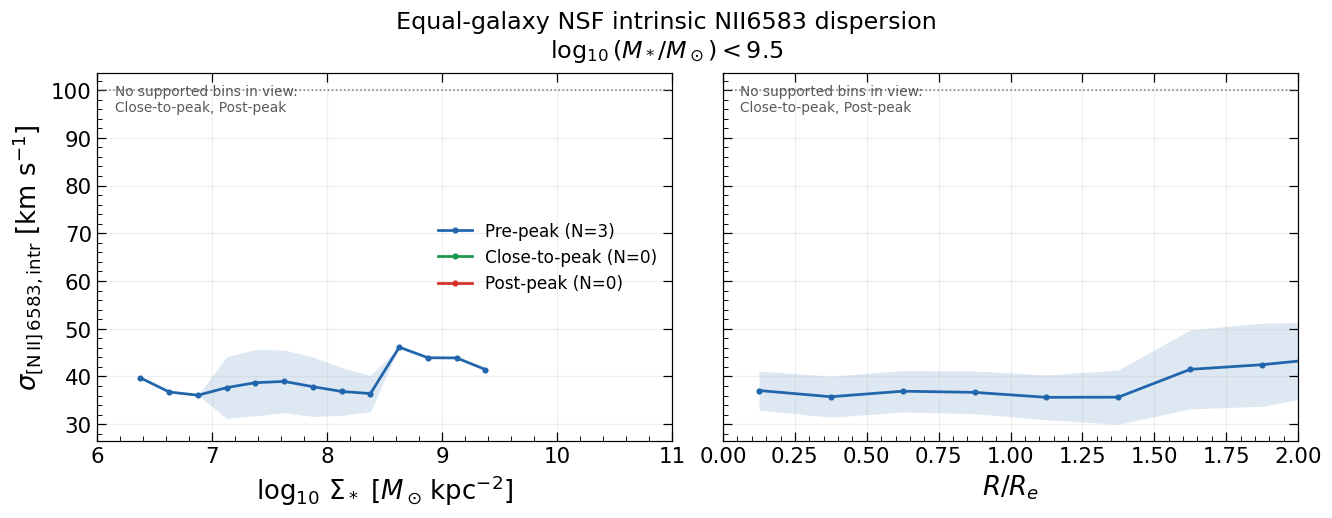

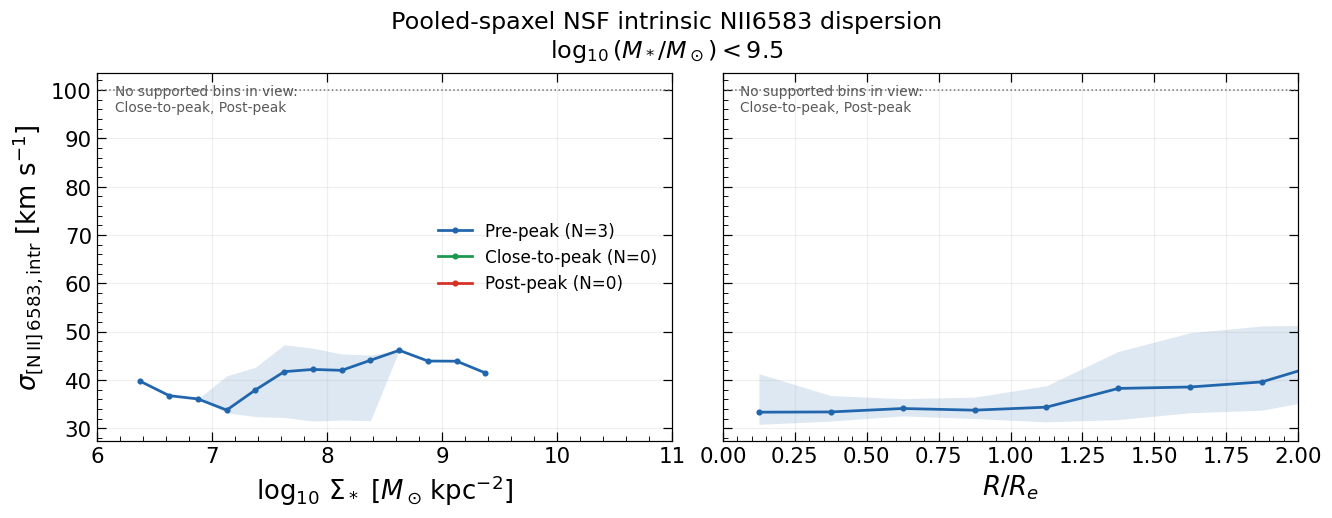

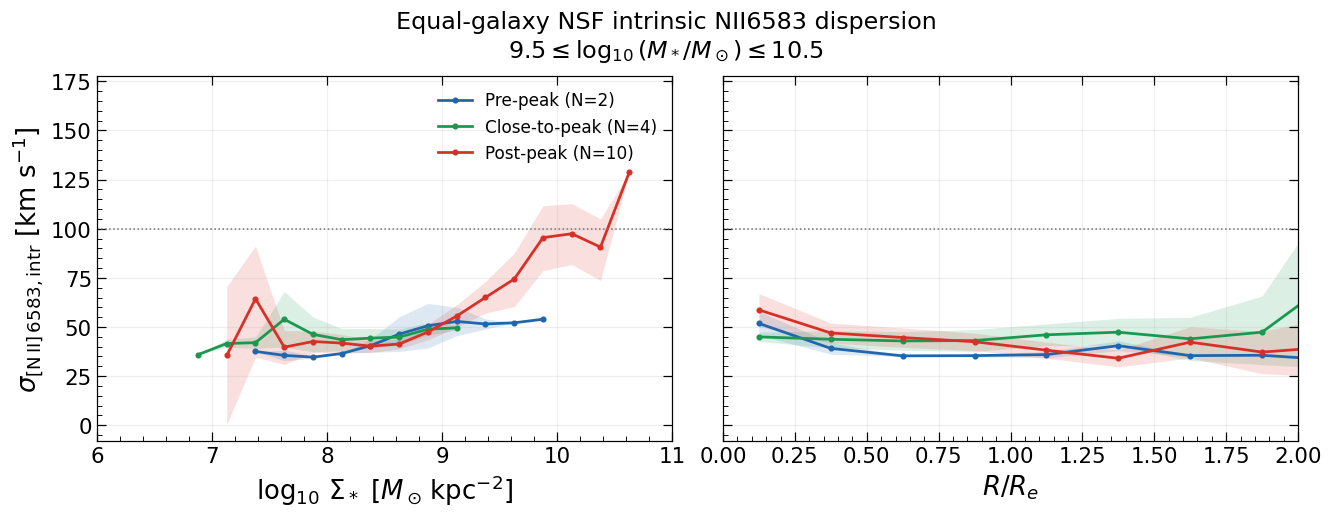

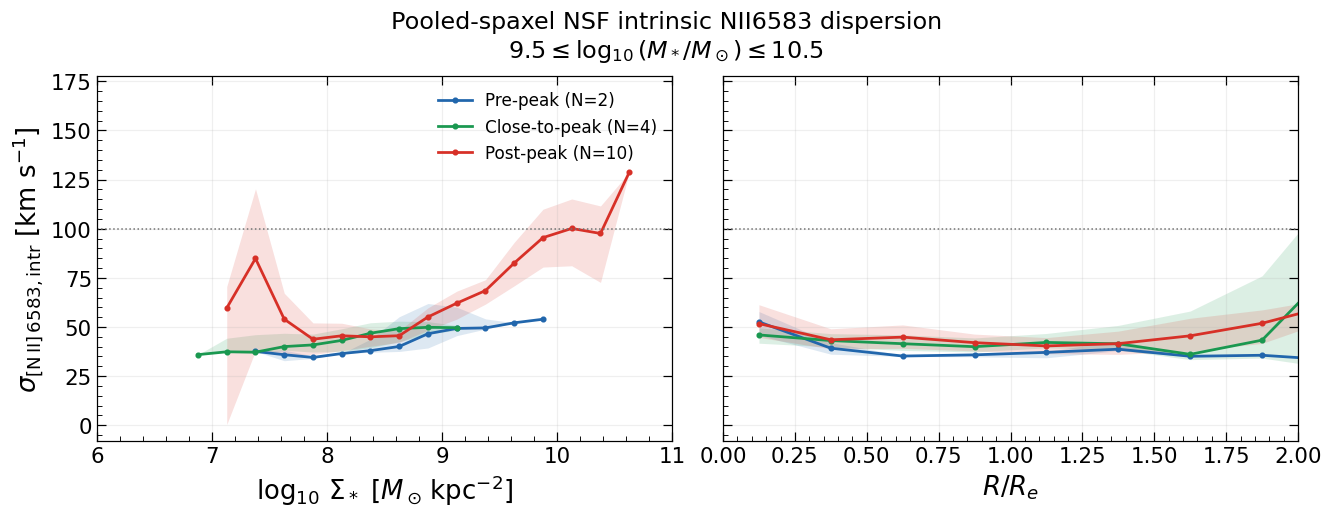

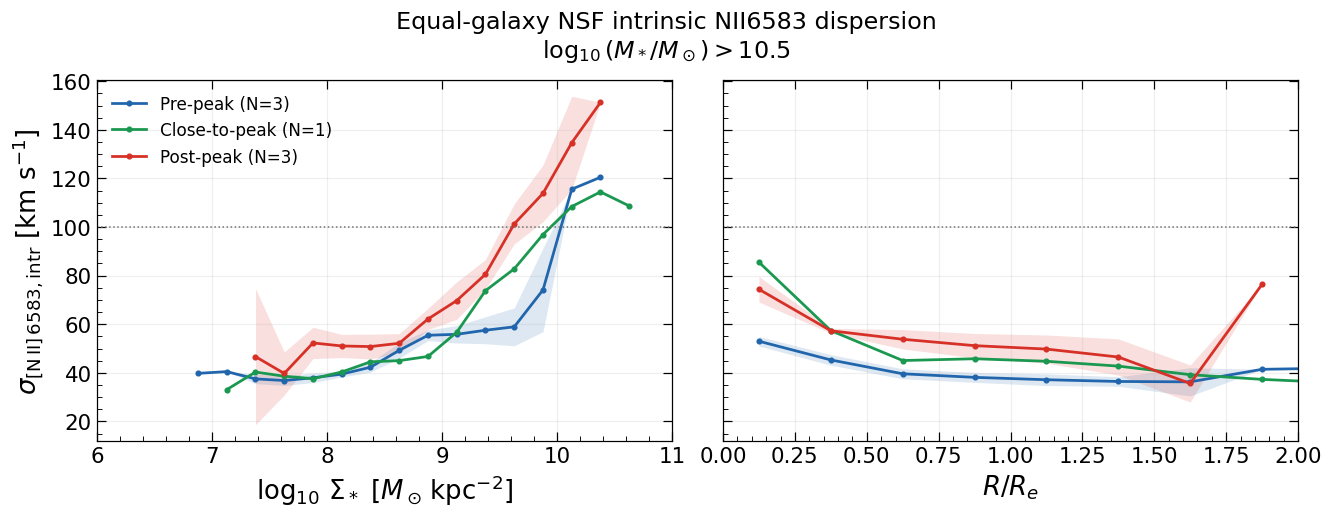

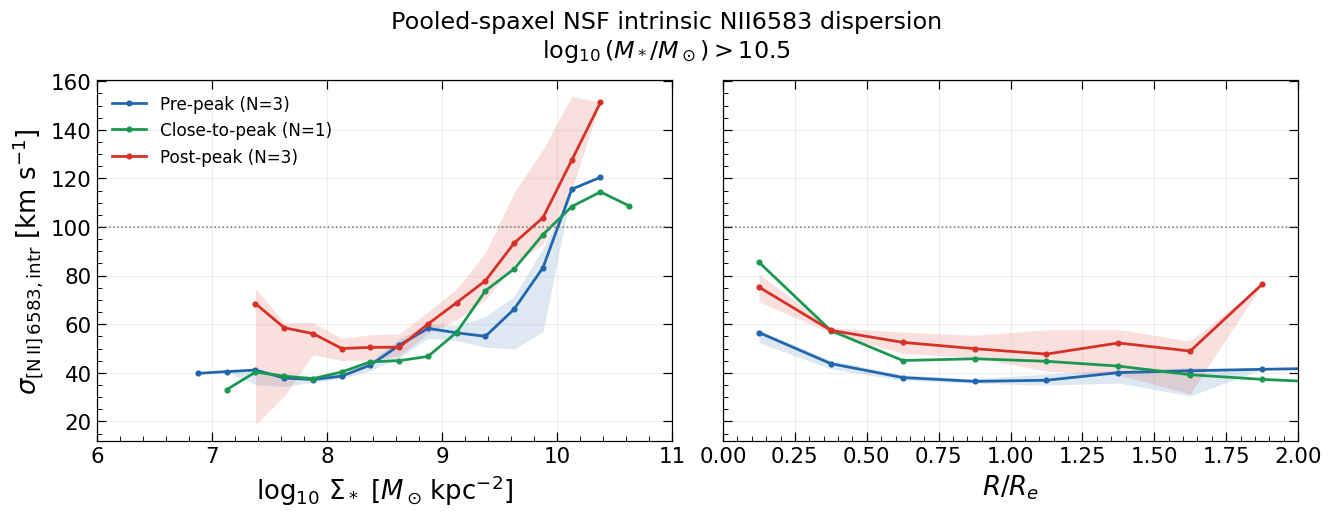

In [8]:
for mass_bin in GLOBAL_MASS_ORDER:
    for branch in ('equal_galaxy', 'pooled_spaxel'):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
        for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
            no_support = []
            for stage in (1, 2, 3):
                p = global_mass_profiles.loc[
                    global_mass_profiles.global_mass_bin.eq(mass_bin) &
                    global_mass_profiles.branch.eq(branch) &
                    global_mass_profiles.stage.eq(stage) &
                    global_mass_profiles.variable.eq(variable)].sort_values('center')
                n_products = int(mass_stage_counts.loc[mass_bin, stage])
                stage_label = f'{STAGE_LABELS[stage]} (N={n_products})'
                ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                        lw=1.8, label=stage_label)
                ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float),
                                p.hi.to_numpy(float), color=STAGE_COLORS[stage],
                                alpha=0.15, linewidth=0)
                xmin, xmax = PROFILE_X_LIMITS[variable]
                shown = p.loc[p.center.between(xmin, xmax)]
                if not shown.N_gal_support.gt(0).any():
                    no_support.append(STAGE_LABELS[stage])
            if no_support:
                ax.text(0.03, 0.97, 'No supported bins in view:\n' + ', '.join(no_support),
                        transform=ax.transAxes, va='top', fontsize=9, color='0.35')
            ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
            ax.set_xlim(PROFILE_X_LIMITS[variable])
            ax.set_xlabel(fraction_labels[variable])
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.2)
        axes[0].set_ylabel(r'$\sigma_{\mathrm{[N\,II]}\,6583,\mathrm{intr}}$ [km s$^{-1}$]')
        axes[0].legend(frameon=False, loc='best')
        label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
        fig.suptitle(label + ' NSF intrinsic NII6583 dispersion\n' + GLOBAL_MASS_LABELS[mass_bin])
        save_figure(fig, 'NSF_intrinsic_NII6583_dispersion_global_mass_' + mass_bin + '_' + branch)
        plt.show()
        plt.close(fig)

## Additional test: two global-mass bins at log10(Mstar/Msun) = 10

Use the requested fixed split **log10(Mstar/Msun) <10** and
**log10(Mstar/Msun) >10**, shared by all three stages. Catalogue masses exactly
equal to 10 are excluded from this comparison and reported explicitly. The
boundary is fixed rather than optimized for equal sample sizes.

Retain NGC4567_8 as one product and bootstrap unit. Classify its two component
catalogue masses separately and require that both lie in the same bin; do not
sum or average them. Report both physical-galaxy and independent-product counts.

Repeat both original weighting schemes versus local stellar surface density and
R/Re, retaining the original masks, profile edges, support gates and 10,000
whole-product bootstrap draws. Stage counts and bin-level support can differ.
The original all-mass and three-bin results above remain unchanged.


In [7]:
TWO_MASS_ORDER = ('lower', 'higher')
two_mass_component_rows = []
for record in counts.itertuples(index=False):
    components = geometry.loc[geometry.notebook_product_id.eq(record.galaxy), 'galaxy'].tolist()
    assert components
    for component in components:
        value = catalog_logmstar[component]
        assert np.isfinite(value), f'{component}: missing global stellar mass'
        two_mass_component_rows.append(dict(
            product=record.galaxy, galaxy=component, stage=record.stage, logMstar=value))
two_mass_components = pd.DataFrame(two_mass_component_rows)
assert not two_mass_components.galaxy.duplicated().any()
assert set(two_mass_components['product']) == set(counts.galaxy)

TWO_MASS_BOUNDARY = 10.0
two_mass_components['two_mass_bin'] = np.select(
    [two_mass_components.logMstar.lt(TWO_MASS_BOUNDARY),
     two_mass_components.logMstar.gt(TWO_MASS_BOUNDARY)],
    ['lower', 'higher'], default='excluded_equal_10')
assert two_mass_components.groupby('product').two_mass_bin.nunique().eq(1).all()
two_mass_product_info = two_mass_components.groupby('product', sort=True).agg(
    two_mass_bin=('two_mass_bin', 'first'), N_physical_galaxies=('galaxy', 'size'),
    component_logMstar_min=('logMstar', 'min'), component_logMstar_max=('logMstar', 'max'))
two_mass_membership = global_mass_membership.merge(
    two_mass_product_info, left_on='galaxy', right_index=True, how='left', validate='one_to_one')
assert two_mass_membership.two_mass_bin.notna().all()
two_mass_excluded_products = two_mass_membership.loc[
    ~two_mass_membership.two_mass_bin.isin(TWO_MASS_ORDER)].copy()
two_mass_membership = two_mass_membership.loc[
    two_mass_membership.two_mass_bin.isin(TWO_MASS_ORDER)].copy()
two_mass_excluded_components = two_mass_components.loc[
    ~two_mass_components.two_mass_bin.isin(TWO_MASS_ORDER)].copy()
two_mass_components = two_mass_components.loc[
    two_mass_components.two_mass_bin.isin(TWO_MASS_ORDER)].copy()
two_mass_stage_counts = pd.crosstab(
    two_mass_membership.two_mass_bin, two_mass_membership.stage).reindex(
        index=TWO_MASS_ORDER, columns=(1, 2, 3), fill_value=0)
two_mass_physical_stage_counts = pd.crosstab(
    two_mass_components.two_mass_bin, two_mass_components.stage).reindex(
        index=TWO_MASS_ORDER, columns=(1, 2, 3), fill_value=0)
assert two_mass_stage_counts.to_numpy().sum() == len(two_mass_membership)
assert len(two_mass_membership) + len(two_mass_excluded_products) == len(counts)
assert two_mass_physical_stage_counts.to_numpy().sum() == len(two_mass_components)
TWO_MASS_LABELS = {
    'lower': rf'$\log_{{10}}(M_*/M_\odot)<{TWO_MASS_BOUNDARY:g}$',
    'higher': rf'$\log_{{10}}(M_*/M_\odot)>{TWO_MASS_BOUNDARY:g}$',
}
print(f'Shared global-mass boundary: log10(Mstar/Msun) = {TWO_MASS_BOUNDARY:.9f}')
print('Lower uses <10; higher uses >10; exact equality is excluded.')
print('Products excluded at exactly 10:', len(two_mass_excluded_products))
display(two_mass_excluded_components)
print('Physical galaxies by stage:')
display(two_mass_physical_stage_counts.rename(columns=STAGE_LABELS))
print('Independent products by stage (bootstrap units):')
display(two_mass_stage_counts.rename(columns=STAGE_LABELS))
display(two_mass_membership[['galaxy', 'stage', 'two_mass_bin', 'N_physical_galaxies',
                            'component_logMstar', 'component_logMstar_min',
                            'component_logMstar_max', 'N_sigma']])


Shared global-mass boundary: log10(Mstar/Msun) = 10.000000000
Lower uses <10; higher uses >10; exact equality is excluded.
Products excluded at exactly 10: 0
Physical galaxies by stage:
Independent products by stage (bootstrap units):


,product,galaxy,stage,logMstar,two_mass_bin


stage,Pre-peak,Close-to-peak,Post-peak
two_mass_bin,,,
lower,4,2,4
higher,5,3,9


stage,Pre-peak,Close-to-peak,Post-peak
two_mass_bin,,,
lower,4,2,4
higher,4,3,9


,galaxy,stage,two_mass_bin,N_physical_galaxies,component_logMstar,component_logMstar_min,component_logMstar_max,N_sigma
0,IC3392,3,lower,1,IC3392: 9.823572,9.823572,9.823572,9123
1,NGC4064,3,higher,1,NGC4064: 10.046130,10.046130,10.046130,33921
2,NGC4189,1,lower,1,NGC4189: 9.734349,9.734349,9.734349,34012
3,NGC4254,1,higher,1,NGC4254: 10.504350,10.504350,10.504350,163358
4,NGC4293,3,higher,1,NGC4293: 10.526728,10.526728,10.526728,63400
5,NGC4294,1,lower,1,NGC4294: 9.364349,9.364349,9.364349,51426
6,NGC4298,2,higher,1,NGC4298: 10.094349,10.094349,10.094349,43104
7,NGC4321,1,higher,1,NGC4321: 10.781281,10.781281,10.781281,329655
8,NGC4351,1,lower,1,NGC4351: 9.354349,9.354349,9.354349,16682
9,NGC4380,3,higher,1,NGC4380: 10.094349,10.094349,10.094349,51190


In [8]:
two_mass_profiles = pd.concat([
    profiles_in_global_mass_bin(
        two_mass_membership.loc[two_mass_membership.two_mass_bin.eq(mass_bin)], mass_bin)
    for mass_bin in TWO_MASS_ORDER
], ignore_index=True).rename(columns={'global_mass_bin': 'two_mass_bin'})
assert len(two_mass_profiles) == 2 * len(nsf_extra_profiles)
assert not two_mass_profiles.duplicated(
    ['two_mass_bin', 'branch', 'stage', 'variable', 'diagnostic', 'left']).any()
display(two_mass_profiles)

# Report support over the plotted coordinate ranges without restricting statistics.
support_summary_rows = []
for (mass_bin, branch, stage, variable), panel in two_mass_profiles.groupby(
        ['two_mass_bin', 'branch', 'stage', 'variable'], sort=False):
    xmin, xmax = PROFILE_X_LIMITS[variable]
    shown = panel.loc[panel.center.between(xmin, xmax)]
    supported = shown.N_gal_support.gt(0)
    support_summary_rows.append(dict(
        two_mass_bin=mass_bin, branch=branch, stage=STAGE_LABELS[stage], variable=variable,
        N_products=int(two_mass_stage_counts.loc[mass_bin, stage]),
        N_display_bins_supported=int(supported.sum()),
        N_display_bins_single_product=int(shown.N_gal_support.eq(1).sum()),
        max_products_per_display_bin=int(shown.N_gal_support.max()) if len(shown) else 0))
two_mass_support_summary = pd.DataFrame(support_summary_rows)
display(two_mass_support_summary)


,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi,two_mass_bin
0,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN,lower
1,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN,lower
2,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.25,6.50,6.375,1,443,6919,39.690235,39.690235,39.690235,lower
3,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.50,6.75,6.625,1,1007,6919,36.738324,36.738324,36.738324,lower
4,equal_galaxy,1,log_sigma_star,sigma_NII6583_intrinsic,6.75,7.00,6.875,1,9163,6919,36.055778,36.055778,36.055778,lower
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN,higher
848,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN,higher
849,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN,higher
850,pooled_spaxel,3,radius_re,sigma_NII6583_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN,higher


,two_mass_bin,branch,stage,variable,N_products,N_display_bins_supported,N_display_bins_single_product,max_products_per_display_bin
0,lower,equal_galaxy,Pre-peak,log_sigma_star,4,13,3,4
1,lower,equal_galaxy,Pre-peak,radius_re,4,8,0,4
2,lower,pooled_spaxel,Pre-peak,log_sigma_star,4,13,3,4
3,lower,pooled_spaxel,Pre-peak,radius_re,4,8,0,4
4,lower,equal_galaxy,Close-to-peak,log_sigma_star,2,9,4,2
5,lower,equal_galaxy,Close-to-peak,radius_re,2,8,0,2
6,lower,pooled_spaxel,Close-to-peak,log_sigma_star,2,9,4,2
7,lower,pooled_spaxel,Close-to-peak,radius_re,2,8,0,2
8,lower,equal_galaxy,Post-peak,log_sigma_star,4,8,2,4
9,lower,equal_galaxy,Post-peak,radius_re,4,8,0,4


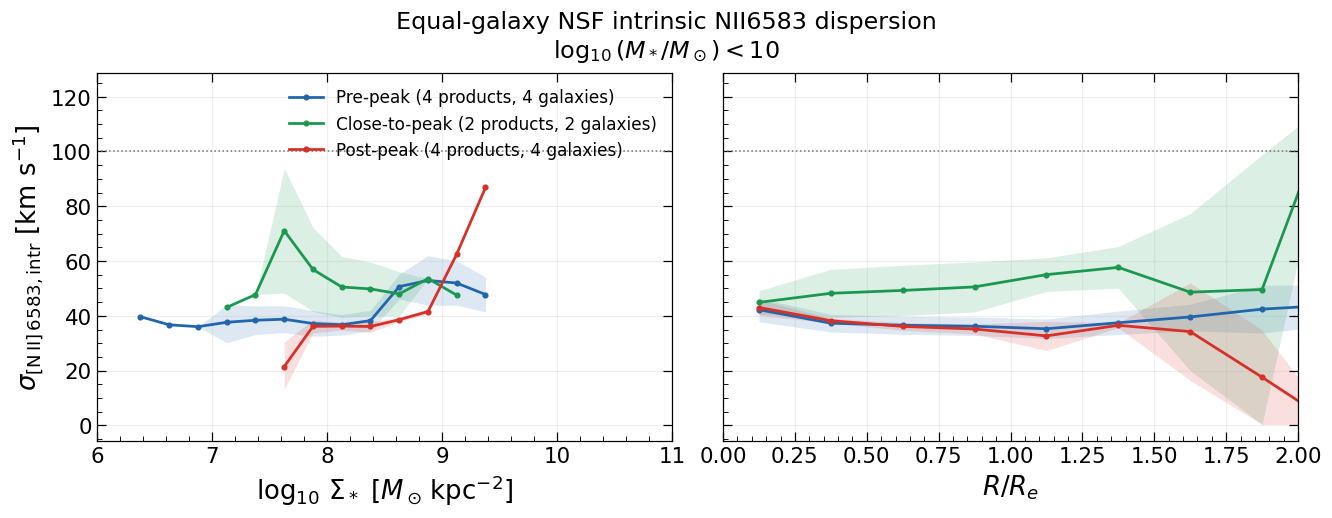

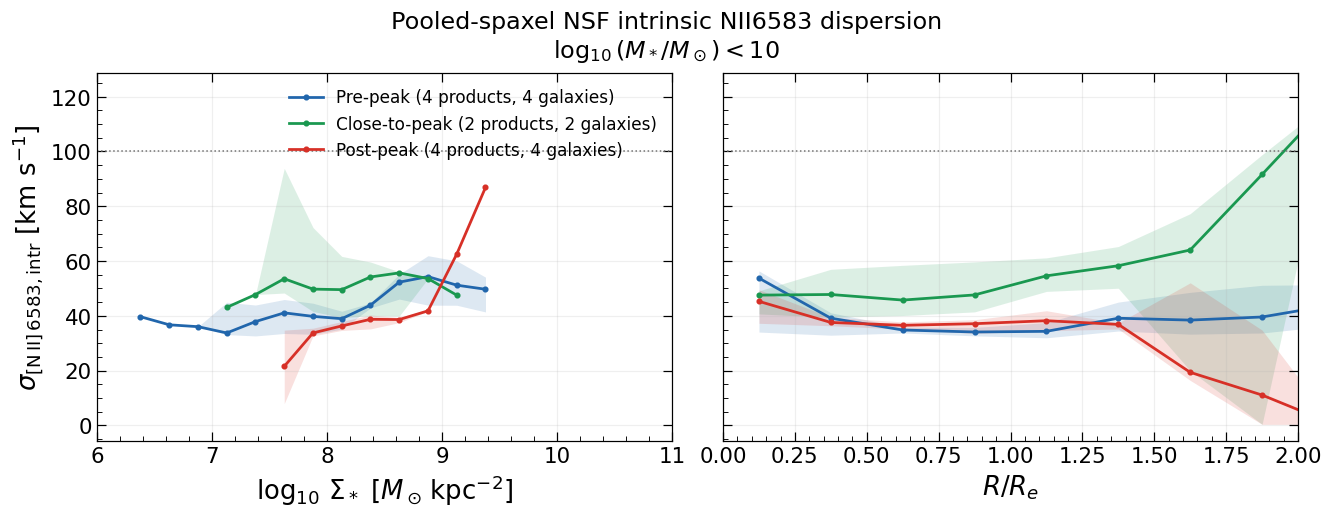

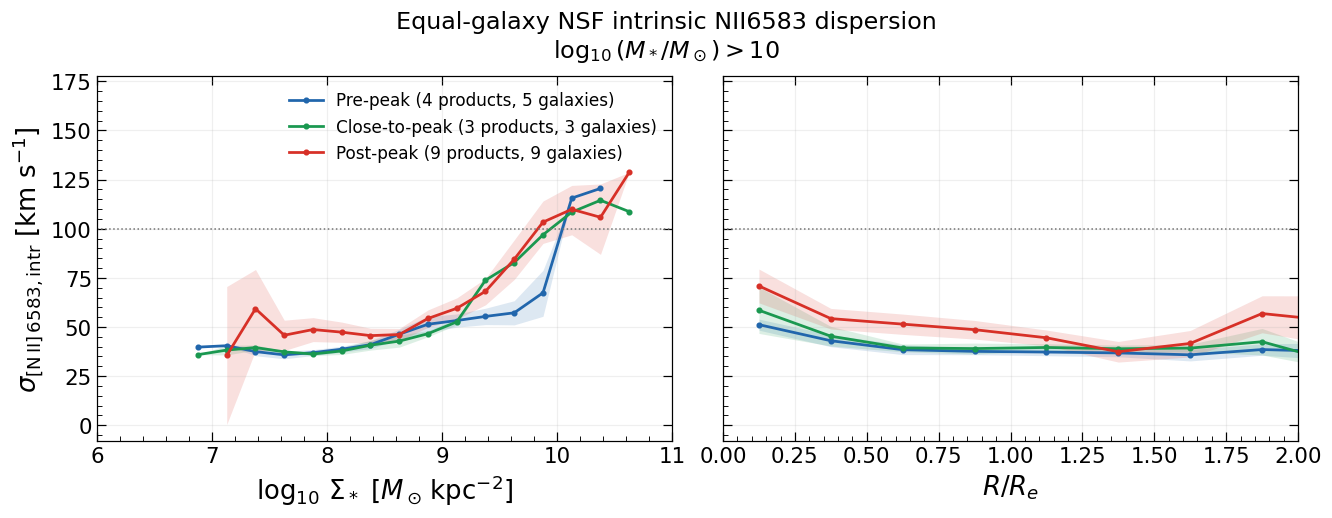

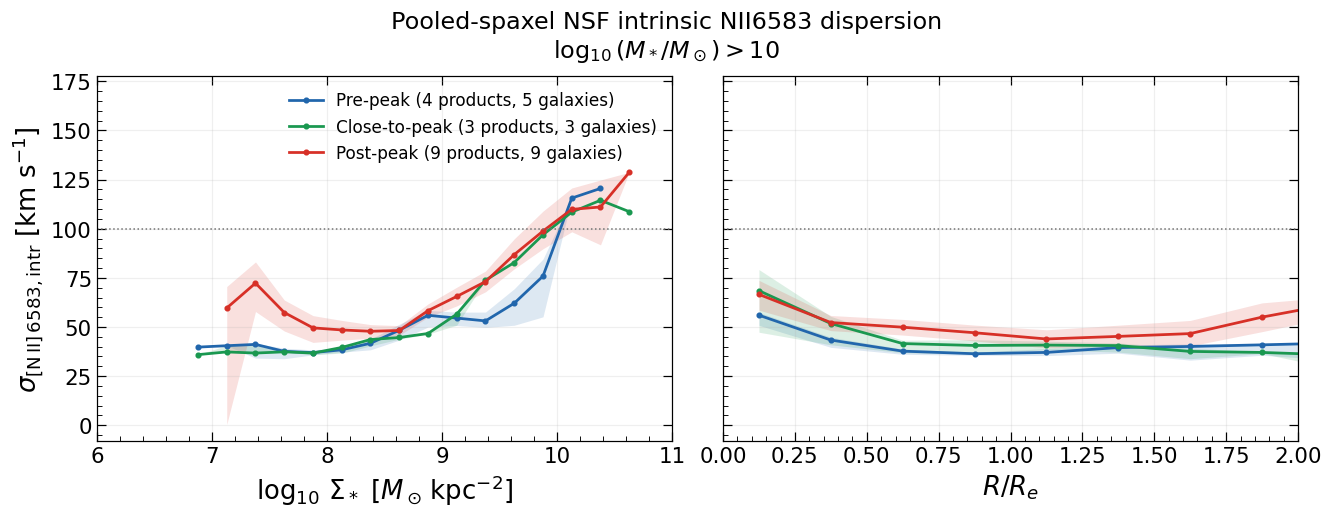

In [9]:
for mass_bin in TWO_MASS_ORDER:
    for branch in ('equal_galaxy', 'pooled_spaxel'):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
        for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
            no_support = []
            for stage in (1, 2, 3):
                p = two_mass_profiles.loc[
                    two_mass_profiles.two_mass_bin.eq(mass_bin) &
                    two_mass_profiles.branch.eq(branch) &
                    two_mass_profiles.stage.eq(stage) &
                    two_mass_profiles.variable.eq(variable)].sort_values('center')
                n_products = int(two_mass_stage_counts.loc[mass_bin, stage])
                n_physical = int(two_mass_physical_stage_counts.loc[mass_bin, stage])
                stage_label = f'{STAGE_LABELS[stage]} ({n_products} products, {n_physical} galaxies)'
                ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                        lw=1.8, label=stage_label)
                ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float),
                                p.hi.to_numpy(float), color=STAGE_COLORS[stage],
                                alpha=0.15, linewidth=0)
                xmin, xmax = PROFILE_X_LIMITS[variable]
                shown = p.loc[p.center.between(xmin, xmax)]
                if not shown.N_gal_support.gt(0).any():
                    no_support.append(STAGE_LABELS[stage])
            if no_support:
                ax.text(0.03, 0.97, 'No supported bins in view:\n' + ', '.join(no_support),
                        transform=ax.transAxes, va='top', fontsize=9, color='0.35')
            ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
            ax.set_xlim(PROFILE_X_LIMITS[variable])
            ax.set_xlabel(fraction_labels[variable])
            ax.tick_params(top=True, right=True)
            ax.minorticks_on()
            ax.grid(alpha=0.2)
        axes[0].set_ylabel(r'$\sigma_{\mathrm{[N\,II]}\,6583,\mathrm{intr}}$ [km s$^{-1}$]')
        axes[0].legend(frameon=False, loc='best')
        label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
        fig.suptitle(label + ' NSF intrinsic NII6583 dispersion\n' + TWO_MASS_LABELS[mass_bin])
        save_figure(fig, 'NSF_intrinsic_NII6583_dispersion_two_mass_split10_' + mass_bin + '_' + branch)
        plt.show()
        plt.close(fig)